# 6장 차원 축소 part A

**범위:** 6.1 차원 축소 개요 · 6.2 PCA · 6.3 LDA  

- `scikit-learn` 내장 데이터만 사용하므로 별도 파일은 필요하지 않습니다.
- 제공된 시작 코드를 바탕으로 `TODO` 부분을 완성해주세요. 필요한 라이브러리나 변수는 추가하셔도 됩니다.
- 각 문항의 해석 질문은 실행 결과를 근거로 **2~3문장**으로 작성해주세요.


## 문제 1. Wine 데이터: 정보를 얼마나 유지하며 차원을 줄일 수 있을까?

Wine 데이터에는 **178개 샘플, 13개 수치 피처, 3개 클래스**가 있습니다.

**(a)** 13개 피처를 표준화한 뒤 PCA를 적용하세요. **누적 설명된 분산 비율이 처음으로 90% 이상**이 되는 최소 주성분 개수를 계산하고, 그때의 누적 설명된 분산 비율을 출력하세요.  
**(b)** (a)에서 찾은 개수만큼 주성분을 남겨 변환하고, 결과 배열의 모양을 출력하세요.  
**(c)** 주성분 개수가 2개일 때의 누적 설명된 분산 비율도 계산한 다음, (a)의 결과와 비교하여 **주성분을 많이 남길수록 얻는 점과 잃는 점**을 설명하세요.

힌트: `explained_variance_ratio_`, `np.cumsum`, `np.argmax`, `PCA(n_components=...)`

In [29]:
import numpy as np
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

X, y = load_wine(return_X_y=True)
X_scaled = StandardScaler().fit_transform(X)

# (a)
pca = PCA()
pca.fit(X_scaled)
cumulative_variance_ratio = np.cumsum(pca.explained_variance_ratio_)
n_components_90 = np.argmax(cumulative_variance_ratio >= 0.90) + 1

print('90% 기준 최소 차원 수:', n_components_90)
print('누적 설명된 분산 비율:', cumulative_variance_ratio[n_components_90 - 1])

# (b)
pca_90 = PCA(n_components=n_components_90)
X_pca_90 = pca_90.fit_transform(X_scaled)
print('shape:', X_pca_90.shape)

# (c)
pca_2 = PCA(n_components=2)
X_pca_2 = pca_2.fit_transform(X_scaled)
print('주성분 2개의 누적 설명된 분산 비율:', np.sum(pca_2.explained_variance_ratio_))

90% 기준 최소 차원 수: 8
누적 설명된 분산 비율: 0.9201754434577263
shape: (178, 8)
주성분 2개의 누적 설명된 분산 비율: 0.5540633835693526


**해석 답안:**

13개 피처를 표준화한 뒤 PCA를 적용한 결과, 누적 설명된 분산 비율이 처음으로 90%를 넘는 최소 주성분 개수는 8개이며 누적 설명된 분산 비율은 약 92.02이며,  데이터는 (178, 8) 형태로 변환된다. 반면 2개 주성분만 남기면 누적 설명된 분산 비율은 약 55.41%이다. 주성분을 많이 남길수록 원본 데이터의 정보와 변동성을 더 많이 보존하지만, 차원 축소 효과와 계산 효율은 감소한다.

## 문제 2. 유방암 진단 데이터: PCA가 분류 성능에 미치는 영향

Breast Cancer Wisconsin 데이터에는 **569개 샘플, 30개 입력 피처, 2개 클래스**가 있습니다. 동일한 `LogisticRegression` 모델을 **원본 피처**와 **PCA로 5개 주성분으로 변환한 피처**에 각각 적용하려고 합니다.

**(a)** 원본 피처와 PCA 변환 피처에 대해 각각 `StandardScaler`가 포함된 `Pipeline`을 만들고, **5-Fold 층화 교차 검증**으로 평균 정확도를 구하세요. (두 모델 모두 동일한 `StratifiedKFold` 사용)  
**(b)** 두 모델의 평균 정확도 차이를 **퍼센트포인트(%p)** 단위로 출력하세요. (PCA 모델 − 원본 모델)  
**(c)** PCA 모델의 정확도가 낮아지거나 높아지더라도, **PCA가 반드시 분류 성능을 개선하는 방법은 아닌 이유**를 발표의 핵심 개념으로 설명하세요.

조건: `random_state=42`, `n_splits=5`, `shuffle=True`로 고정하세요. PCA는 **Pipeline 내부**에 배치합니다.

힌트: `make_pipeline`, `cross_val_score`, `StratifiedKFold`

In [30]:
import numpy as np
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline

X, y = load_breast_cancer(return_X_y=True)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# (a)
original_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)
pca_model = make_pipeline(
    StandardScaler(),
    PCA(n_components=5),
    LogisticRegression(max_iter=1000)
)

original_scores = cross_val_score(
    original_model, X, y, cv=cv, scoring='accuracy'
)
pca_scores = cross_val_score(
    pca_model, X, y, cv=cv, scoring='accuracy'
)

print('원본 피처 평균 정확도: {:.4f}'.format(np.mean(original_scores)))
print('PCA 피처 평균 정확도: {:.4f}'.format(np.mean(pca_scores)))

# (b)
accuracy_diff = (np.mean(pca_scores) - np.mean(original_scores)) * 100
print('평균 정확도 차이: {:.2f}%p'.format(accuracy_diff))

원본 피처 평균 정확도: 0.9737
PCA 피처 평균 정확도: 0.9631
평균 정확도 차이: -1.05%p


**해석 답안:**

원본 피처 모델의 5-Fold 평균 정확도는 약 97.37%, PCA로 5개 주성분만 사용한 모델은 약 96.31%이며, 차이는 -1.05%p이다. PCA는 분산이 큰 방향을 기준으로 차원을 축소하므로 데이터의 전체 변동성을 효율적으로 보존하지만, 분류에 중요한 정보가 반드시 큰 분산을 갖는 것은 아니다. 따라서 PCA는 지도학습의 분류 성능을 반드시 개선하는 방법은 아니다.

## 문제 3. Wine 데이터: PCA와 LDA의 차원을 줄이는 기준 비교

문제 1의 Wine 데이터를 활용해 **13차원 → 2차원**으로 축소한 뒤, PCA와 LDA 결과를 비교하세요.

**(a)** `train_test_split(test_size=0.3, stratify=y, random_state=42)`로 학습·평가 데이터를 분리하고, 학습 데이터로만 `StandardScaler`를 학습해 두 데이터에 적용하세요. 그다음 **PCA(2개)**와 **LDA(2개)**를 각각 학습 데이터로 학습하여 학습·평가 데이터를 변환하세요. 결과 배열의 모양을 출력하세요. LDA에는 클래스 레이블을 입력해야 합니다.  
**(b)** 각각의 2차원 학습 데이터에 `LogisticRegression`을 학습하고, 평가 데이터 정확도를 출력하세요.  
**(c)** 두 방법이 서로 다른 결과를 내는 이유를 **사용하는 레이블과 축을 선택하는 기준**이라는 두 관점에서 설명하세요. 정확도가 높게 나온 방법이 모든 데이터에서 우월하다고 단정할 수 있는지도 덧붙이세요.

힌트: `LinearDiscriminantAnalysis(n_components=2)`, `fit_transform(X_train_scaled, y_train)`, `accuracy_score`

In [31]:
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

X, y = load_wine(return_X_y=True)

# (a)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

lda = LinearDiscriminantAnalysis(n_components=2)
X_train_lda = lda.fit_transform(X_train_scaled, y_train)
X_test_lda = lda.transform(X_test_scaled)

print('PCA 학습 데이터:', X_train_pca.shape)
print('PCA 평가 데이터:', X_test_pca.shape)
print('LDA 학습 데이터:', X_train_lda.shape)
print('LDA 평가 데이터:', X_test_lda.shape)

# (b)
pca_model = LogisticRegression(max_iter=1000)
pca_model.fit(X_train_pca, y_train)
pca_pred = pca_model.predict(X_test_pca)
pca_accuracy = accuracy_score(y_test, pca_pred)

lda_model = LogisticRegression(max_iter=1000)
lda_model.fit(X_train_lda, y_train)
lda_pred = lda_model.predict(X_test_lda)
lda_accuracy = accuracy_score(y_test, lda_pred)

print('PCA 정확도: {:.4f}'.format(pca_accuracy))
print('LDA 정확도: {:.4f}'.format(lda_accuracy))

PCA 학습 데이터: (124, 2)
PCA 평가 데이터: (54, 2)
LDA 학습 데이터: (124, 2)
LDA 평가 데이터: (54, 2)
PCA 정확도: 0.9444
LDA 정확도: 0.9815


**해석 답안:**

PCA와 LDA 모두 Wine 데이터를 13차원에서 2차원으로 변환하므로 학습 데이터는 (124, 2), 평가 데이터는 (54, 2) 형태이다. PCA 기반 LogisticRegression의 정확도는 약 94.44%, LDA 기반 모델은 약 98.15%이다. PCA는 타깃 레이블을 사용하지 않고 데이터의 분산이 가장 큰 축을 찾는 비지도학습 방식인 반면, LDA는 클래스 레이블을 사용하여 클래스 간 분산은 크게, 클래스 내부 분산은 작게 하는 축을 찾는 지도학습 방식이다. 따라서 이번 데이터에서는 LDA의 정확도가 높지만, 데이터 특성과 분할에 따라 결과가 달라지므로 모든 데이터에서 LDA가 항상 우월하다고 단정할 수 없다.

# **문제 4. SVD를 이용한 행렬 분해 및 복원**

## **4-1. 행렬 분해**

SVD를 이용하여 5x5 행렬 a를 분해 해주세요.

In [32]:
import numpy as np
from numpy.linalg import svd

np.random.seed(10)
a = np.random.randn(5, 5)

U, Sigma, Vt = svd(a)

print('Origianl matrix a:\n', np.round(a, 3))
print('\nU matrix:\n', np.round(U, 3))
print('\nSigma matrix:\n', np.round(Sigma, 3))
print('\nV transpose matrix:\n', np.round(Vt, 3))

Origianl matrix a:
 [[ 1.332  0.715 -1.545 -0.008  0.621]
 [-0.72   0.266  0.109  0.004 -0.175]
 [ 0.433  1.203 -0.965  1.028  0.229]
 [ 0.445 -1.137  0.135  1.485 -1.08 ]
 [-1.978 -1.743  0.266  2.385  1.124]]

U matrix:
 [[-0.34   0.653 -0.057  0.53   0.416]
 [ 0.06  -0.106 -0.18  -0.506  0.835]
 [-0.116  0.668 -0.086 -0.655 -0.322]
 [ 0.291  0.183  0.923 -0.065  0.161]
 [ 0.884  0.286 -0.325  0.174  0.008]]

Sigma matrix:
 [4.077 2.543 1.952 1.107 0.3  ]

V transpose matrix:
 [[-0.531 -0.549  0.225  0.595  0.106]
 [ 0.295  0.211 -0.615  0.643  0.276]
 [ 0.548 -0.346  0.097  0.259 -0.71 ]
 [ 0.373 -0.698 -0.185 -0.327  0.483]
 [-0.437 -0.218 -0.726 -0.242 -0.419]]


## **4-2. 행렬 복원**

분해한 행렬을 복원해 주세요.

In [33]:
# Sigma를 대각행렬로 변환
Sigma_mat = np.diag(Sigma)

# U, Sigma, Vt를 이용하여 원본 행렬 복원
a_ = np.dot(np.dot(U, Sigma_mat), Vt)

print(np.round(a_, 3))

[[ 1.332  0.715 -1.545 -0.008  0.621]
 [-0.72   0.266  0.109  0.004 -0.175]
 [ 0.433  1.203 -0.965  1.028  0.229]
 [ 0.445 -1.137  0.135  1.485 -1.08 ]
 [-1.978 -1.743  0.266  2.385  1.124]]


## **4-3. 위 코드에서 Sigma의 shape를 작성해 주세요.**

(5,)

# **문제 5. Truncated SVD를 이용한 차원 축소**
다음은 Wine 데이터셋에 Truncated SVD를 적용하여 13차원 데이터를 2차원으로 축소하는 코드입니다.

\## 답안 ## 에 알맞은 코드를 작성해 주세요.

## **5-1. 차원 축소**

2차원으로 축소해주세요.

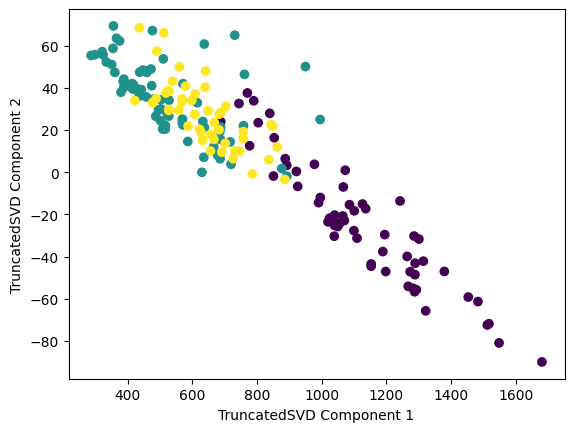

In [34]:
from sklearn.decomposition import TruncatedSVD
from sklearn.datasets import load_wine
import matplotlib.pyplot as plt
%matplotlib inline

wine = load_wine()
wine_ftrs = wine.data

tsvd = TruncatedSVD(n_components=2)

tsvd.fit(wine_ftrs)
wine_tsvd = tsvd.transform(wine_ftrs)

# 시각화
plt.scatter(
    x=wine_tsvd[:, 0],
    y=wine_tsvd[:, 1],
    c=wine.target
)
plt.xlabel('TruncatedSVD Component 1')
plt.ylabel('TruncatedSVD Component 2')
plt.show()

# **문제 6. SVD와 Truncated SVD 비교**

#### **SVD와 Truncated SVD의 차이점을 사용되는 특이값의 개수와 행렬 복원 시 정보 손실여부를 중심으로 서술해 주세요.**

일반적인 SVD는 행렬의 특이값을 모두 사용하여 분해하므로 전체 행렬을 사용하면 원본 행렬을 손실 없이 정확하게 복원할 수 있는 반면, Truncated SVD는 상위 일부 특이값과 이에 대응하는 성분만 사용하여 저차원 행렬로 분해하므로 차원을 줄일 수 있지만 정보 손실이 발생하여 원본행렬을 근사적으로 복원한다.

## 다른 차원의 축소 기법들 개념 복습

# **문제 7.**  
 Discord에 공유된 핸즈온 머신러닝pdf의 '8.6 다른 차원축소 기법들(p. 295 ~ 296)' 혹은 Week10 발표 ppt 속 '#06 다른 차원의 축소 기법들' 파트 내용을 참고해서 랜덤 투영 알고리즘, MDS, ISomap, t-SNE 중 하나의 차원 축소 기법을 골라 간단히 설명하세요.

랜덤 투영은 고차원 데이터에 무작위로 생성한 투영 행렬을 곱해 저차원 공간으로 변환하는 차원 축소 기법이다. 데이터 간의 거리를 완벽하게 보존하지는 않지만 적절한 저차원 공간에서는 데이터 포인트 사이의 거리와 구조를 확률적으로 근사 보존한다. 계산이 비교적 빠르고 고차원, 대규모 데이터에 적용하기 쉽다는 장점이 있다.

## 여러가지 차원 축소 기법들 적용하기

# 문제 8. Dimensionality Reduction for Beginners
8-1)  `PCA`, `MDS`, `t-SNE`각각의 코드를 완성해 실행하세요.   
8-2) 세 기법의 차이를 간단히 서술하세요.

In [35]:
#데이터 로딩하기

%matplotlib inline

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
import matplotlib.patches as mpatches
import seaborn as sns
from sklearn.datasets import load_breast_cancer #Loading the full DataSet From Sklearn Library

# Breast cancer dataset
cancer = load_breast_cancer()
(X_canc, y_canc) = load_breast_cancer(return_X_y = True)

In [36]:
#시각화 함수 만들기

def plot_labelled_scatter(X, y, class_labels,s):
    num_labels = len(class_labels)
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

    marker_array = ['o', '^', '*']
    color_array = ['#FFFF00', '#00AAFF', '#000000', '#FF00AA']
    cmap_bold = ListedColormap(color_array)
    bnorm = BoundaryNorm(np.arange(0, num_labels + 1, 1), ncolors=num_labels)
    plt.figure(figsize=s)

    plt.scatter(X[:, 0], X[:, 1], s=80, c=y, cmap=cmap_bold, norm = bnorm, alpha = 0.4, edgecolor='black', lw = 1)
    sp = plt.gca().spines
    sp['top'].set_visible(False)
    sp['right'].set_visible(False)

    plt.grid(which='both',color='lightslategrey',alpha=0.3)

    plt.xlim(x_min, x_max)
    plt.ylim(y_min, y_max)

    h = []
    for c in range(0, num_labels):
        h.append(mpatches.Patch(color=color_array[c], label=class_labels[c]))
    plt.legend(handles=h,fontsize=15,frameon=False)

8-1) `PCA`, `MDS`, `t-SNE` 코드 완성하기

PCA 코드 완성하기

In [37]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

canc_norm = StandardScaler().fit(X_canc).transform(X_canc)

pca = PCA(n_components=2).fit(canc_norm)

canc_pca = pca.transform(canc_norm)

print('Number of Features in Breat Cancer DataSet Before PCA : {}\\n\\nNumber of Features in Breast Cancer DataSet After PCA : {}'
      .format(X_canc.shape[1], canc_pca.shape[1]))

Number of Features in Breat Cancer DataSet Before PCA : 30\n\nNumber of Features in Breast Cancer DataSet After PCA : 2


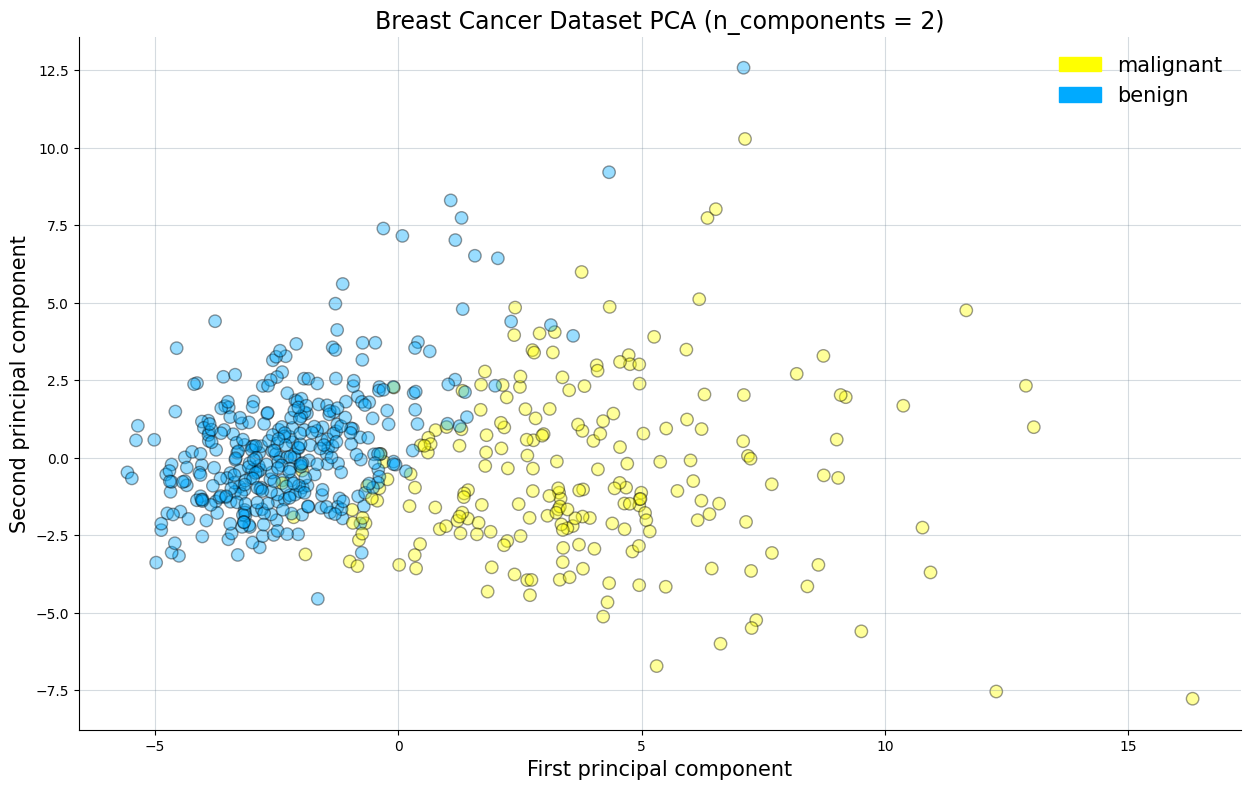

In [38]:
# 앞서 만든 함수 사용
plot_labelled_scatter(canc_pca, y_canc, ['malignant', 'benign'], (15, 9))

# Labelling
plt.xlabel('First principal component', fontsize=15)
plt.ylabel('Second principal component', fontsize=15)
plt.title('Breast Cancer Dataset PCA (n_components = 2)', fontsize=17);

MSD 코드 완성하기

In [ ]:
from sklearn.manifold import MDS

mds = MDS(n_components=2, random_state=2)  #이때 n_components = 2,random_state = 2로 두기

canc_mds = mds.fit_transform(canc_norm)

print('Number of Features in Breat Cancer DataSet Before MDS : {}\n\nNumber of Features in Breast Cancer DataSet After MDS : {}'
      .format(X_canc.shape[1], canc_mds.shape[1]))

plot_labelled_scatter(canc_mds, y_canc, ['malignant', 'benign'], (15, 9))

plt.xlabel('First MDS dimension', fontsize=15)
plt.ylabel('Second MDS dimension', fontsize=15)
plt.title('Breast Cancer Dataset MDS (n_components = 2)', fontsize=17);

t-SNE 코드 완성하기

In [ ]:
from sklearn.manifold import TSNE

tsne = TSNE(n_components=2, random_state=42)  #이때 random_state = 42로 두기

canc_tsne = tsne.fit_transform(canc_norm)

print('Number of Features in Breat Cancer DataSet Before T-SNE : {}\\n\\nNumber of Features in Breast Cancer DataSet After T-SNE : {}'
      .format(X_canc.shape[1], canc_tsne.shape[1]))

plot_labelled_scatter(canc_tsne, y_canc, ['malignant', 'benign'], (15, 9))

plt.xlabel('First T-SNE Dimension', fontsize=14)
plt.ylabel('Second T-SNE Dimension', fontsize=14)
plt.title('Breast Cancer Dataset T-SNE', fontsize=17);

8-2) 세 기법의 차이를 간단히 서술하세요.

답:
세 기법은 차원 축소의 기준이 서로 다르다. PCA는 전체 분산, MDS는 데이터 간 거리, t-SNE는 가까운 이웃의 유사도 보존